# Phân tích khám phá SOH
Đọc trực tiếp bốn file MATLAB từ bản lưu công khai dẫn nguồn NASA. Notebook mô tả dữ liệu và kết quả; không chọn đặc trưng bằng điểm test.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / 'reports/features.csv').exists()
data = pd.read_csv(ROOT / 'reports/features.csv')
audit = pd.read_csv(ROOT / 'reports/data_audit.csv')
audit

,battery,rows_before,all_rows,charge_rows,rows,invalid_rows_removed,duplicates_removed,missing_values,charge_cycles,cycles,min_soh_pct,max_soh_pct
0,B0005,591458,591458,541173,50285,0,0,0,170,168,64.372626,92.824371
1,B0006,591458,591458,541173,50285,0,0,0,170,168,57.690917,101.766880
2,B0007,591458,591458,541173,50285,0,0,0,170,168,70.022762,94.552615
3,B0018,314676,314674,279808,34866,2,0,0,134,132,67.052572,92.750226


## Thống kê từng pin
2.089.048 dòng sạch sau khi loại 2 dòng sạc thiếu tín hiệu; 636 chu kỳ xả thuộc 4 pin. Hai triệu dòng đo không phải hai triệu mẫu nhãn. SOH tính theo 2 Ah; giữ cả giá trị trên 100%.

In [2]:
data.groupby('battery').agg(cycles=('cycle', 'count'), min_soh=('soh_pct', 'min'), max_soh=('soh_pct', 'max'))

,cycles,min_soh,max_soh
battery,,,
B0005,168,64.372626,92.824371
B0006,168,57.690917,101.766880
B0007,168,70.022762,94.552615
B0018,132,67.052572,92.750226


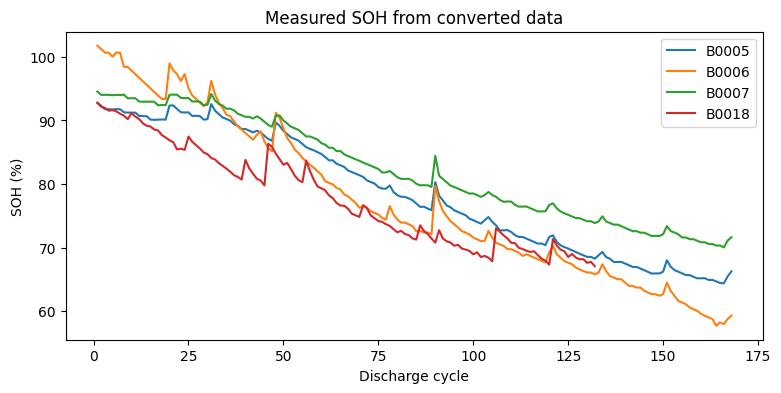

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for battery, group in data.groupby('battery'):
    ax.plot(group.cycle, group.soh_pct, label=battery)
ax.set(xlabel='Discharge cycle', ylabel='SOH (%)', title='Measured SOH from converted data')
ax.legend()
plt.show()

## Tương quan mô tả
Tương quan trên dữ liệu gộp không chứng minh quan hệ nhân quả hoặc giá trị dự đoán trên pin mới. Không dùng biểu đồ này để chọn đặc trưng dựa trên test.

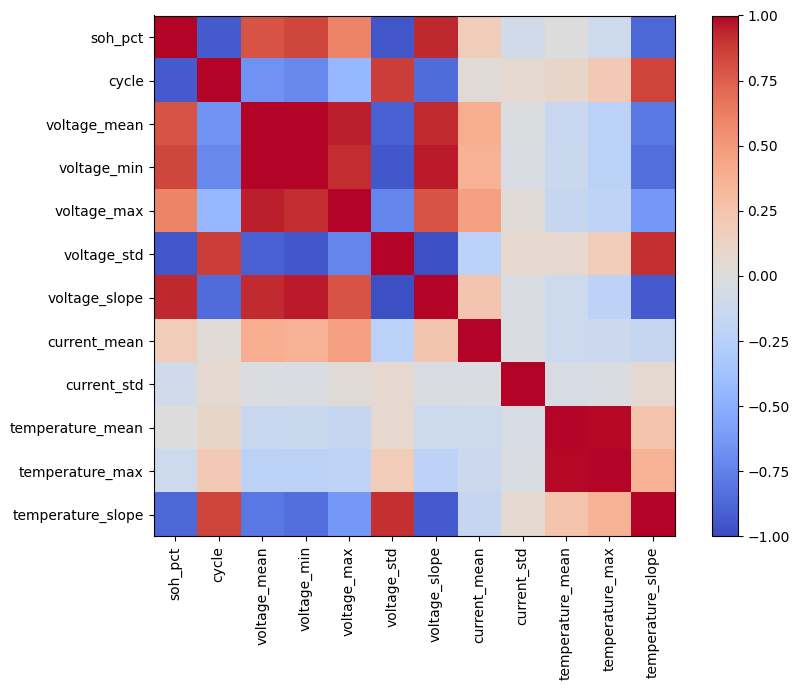

In [4]:
corr = data.drop(columns='battery').corr()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

## Kết quả leave-one-battery-out
MAE/RMSE đo bằng điểm phần trăm SOH; trung bình không trọng số giữa 4 pin. Chưa đủ kết luận về xe điện thực tế hoặc Việt Nam.

In [5]:
pd.read_csv(ROOT / 'reports/metrics_summary.csv')

,model,mae,rmse,r2
0,Mean baseline,8.593756,9.811422,-0.090163
1,Cycle Ridge,4.074429,4.473786,0.690478
2,Signal Ridge,7.405354,7.711533,-0.262123
3,Random Forest,2.724044,3.189112,0.877999
4,HistGradientBoosting,3.285829,3.607904,0.842847


In [6]:
pd.read_csv(ROOT / 'reports/metrics_by_battery.csv')

,model,held_out_battery,n_train,n_test,mae,rmse,r2
0,Mean baseline,B0005,468,168,8.561280,9.512599,-0.004290
1,Cycle Ridge,B0005,468,168,1.252829,1.536943,0.973783
2,Signal Ridge,B0005,468,168,1.535172,1.972881,0.956802
3,Random Forest,B0005,468,168,1.602679,2.150589,0.948669
4,HistGradientBoosting,B0005,468,168,2.296822,2.612541,0.924249
5,Mean baseline,B0006,468,168,11.348865,12.784927,-0.035422
6,Cycle Ridge,B0006,468,168,4.532625,4.899257,0.847952
7,Signal Ridge,B0006,468,168,6.118896,6.563018,0.727147
8,Random Forest,B0006,468,168,3.979058,4.627421,0.864357
9,HistGradientBoosting,B0006,468,168,4.482542,5.010763,0.840952


## Kiểm tra dataset
CSV đã so từng mảng tín hiệu với file MATLAB của bản lưu, sau khi loại 2 bản ghi sạc thiếu. Nguồn S3 của nhà phát hành chưa truy cập được; không đồng nhất checksum bản lưu với xác nhận từ NASA.

In [7]:
import json
json.loads((ROOT / 'reports/dataset_check.json').read_text())

{'status': 'passed',
 'measurement_rows': 2089048,
 'minimum_rows': 2000000,
 'missing_values': 0,
 'duplicate_measurement_keys': 0,
 'source_arrays_match': True,
 'relative_tolerance': 1e-12,
 'feature_rows': 636,
 'independent_batteries': 4,
 'per_battery_operation': [{'battery': 'B0005',
   'type': 'charge',
   'rows': 541173},
  {'battery': 'B0005', 'type': 'discharge', 'rows': 50285},
  {'battery': 'B0006', 'type': 'charge', 'rows': 541173},
  {'battery': 'B0006', 'type': 'discharge', 'rows': 50285},
  {'battery': 'B0007', 'type': 'charge', 'rows': 541173},
  {'battery': 'B0007', 'type': 'discharge', 'rows': 50285},
  {'battery': 'B0018', 'type': 'charge', 'rows': 279808},
  {'battery': 'B0018', 'type': 'discharge', 'rows': 34866}],
 'csv_sha256': '1b53735124203c2ef1290ba08a85254f6cc5b690a6344c9b2cbcac14faa1d5fa',
 'note': 'Over 2M measurements, not 2M independent SOH samples. MAT mirror, not publisher-byte-verified.'}

## Phân tích bổ sung
Kết quả theo thời gian khác bài toán pin mới; không gộp điểm số. RF không hơn baseline SOH cuối đã biết trong thiết kế 70/30 hiện tại.

In [8]:
pd.read_csv(ROOT / 'reports/ablation_summary.csv')

,configuration,mae,rmse
0,Full features,2.724044,3.189112
1,Without cycle,2.768338,3.349398
2,Without temperature,2.590274,3.048315


In [9]:
pd.read_csv(ROOT / 'reports/temporal_metrics.csv')

,battery,model,n_train,n_test,last_train_cycle,first_test_cycle,mae,rmse
0,B0005,Random Forest,117,51,117,118,4.452559,4.857024
1,B0005,Last known SOH,117,51,117,118,3.307524,3.768651
2,B0006,Random Forest,117,51,117,118,5.473731,6.371544
3,B0006,Last known SOH,117,51,117,118,4.542259,5.501906
4,B0007,Random Forest,117,51,117,118,3.667426,4.055734
5,B0007,Last known SOH,117,51,117,118,2.766036,3.209842
6,B0018,Random Forest,92,40,92,93,2.569571,2.810543
7,B0018,Last known SOH,92,40,92,93,2.101829,2.391037
